# Week 3 Phase 2: Multi-Model Local Comparison (PAN + Aadhaar)

Reads the raw per-image extraction caches produced by `run_local_comparison.py` (real PAN/Aadhaar cards, 5 local models via Ollama) and the manually-transcribed ground-truth subsample from `label_ground_truth.py`, and reports three complementary signals per model per document type:

- **Well-formed rate** -- does the output even look like a valid field (right shape), regardless of correctness?
- **Cross-model agreement** -- across all 5 models, how often does a model's answer match the majority answer? A standard accuracy proxy when no ground truth exists at scale.
- **Manual ground-truth accuracy** -- on a small (~15-20 image/doc-type) manually labeled subsample, the one real, defensible accuracy number, used to sanity-check that agreement actually tracks correctness.

**PII discipline**: this notebook reads two gitignored, real-PII-bearing caches (`poc/real_data_cache/`, `poc/manual_ground_truth_cache/`) but only ever computes and saves *aggregate* numbers -- never prints or persists an actual extracted name/DOB/PAN/Aadhaar number. `poc/model_comparison_summary.json`, this notebook's own saved output, and all charts are safe to commit and share.

In [1]:
import json
import statistics
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import sys

sys.path.insert(0, ".")
from extraction_lib import MODELS, FIELD_NAMES, normalize, field_is_well_formed

DOC_TYPES = ["pan", "aadhaar"]
CACHE_DIR = Path("real_data_cache")
GT_DIR = Path("manual_ground_truth_cache")
SUMMARY_FILE = "model_comparison_summary.json"


## 1. Load raw caches (real PII -- stays in memory only, never printed)

In [2]:
def load_model_cache(doc_type, model_name):
    """Returns {image_name: fields_dict} for one (doc_type, model) pair, or {} if not run yet."""
    safe_model = model_name.replace(":", "_")
    path = CACHE_DIR / f"{doc_type}__{safe_model}.jsonl"
    if not path.exists():
        return {}
    out = {}
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            rec = json.loads(line)
            out[rec["image"]] = {"fields": rec["fields"], "latency": rec["latency"]}
    return out


raw = {doc_type: {model: load_model_cache(doc_type, model) for model in MODELS} for doc_type in DOC_TYPES}

print("Images loaded per (doc_type, model) -- counts only, no PII:")
for doc_type in DOC_TYPES:
    for model in MODELS:
        print(f"  {doc_type:<8} {model:<20} {len(raw[doc_type][model])}")


Images loaded per (doc_type, model) -- counts only, no PII:
  pan      qwen2.5vl:7b         100
  pan      qwen2.5vl:3b         100
  pan      llama3.2-vision:11b  100
  pan      minicpm-v            100
  pan      llava-phi3           100
  aadhaar  qwen2.5vl:7b         103
  aadhaar  qwen2.5vl:3b         103
  aadhaar  llama3.2-vision:11b  103
  aadhaar  minicpm-v            103
  aadhaar  llava-phi3           103


## 2. Well-formedness + latency

In [3]:
wellformed_stats = {}  # wellformed_stats[doc_type][model][field] = rate
latency_stats = {}      # latency_stats[doc_type][model] = {"avg":..., "median":...}

for doc_type in DOC_TYPES:
    wellformed_stats[doc_type] = {}
    latency_stats[doc_type] = {}
    for model in MODELS:
        entries = raw[doc_type][model]
        if not entries:
            continue
        latencies = [e["latency"] for e in entries.values()]
        latency_stats[doc_type][model] = {
            "avg": statistics.mean(latencies),
            "median": statistics.median(latencies),
        }
        field_rates = {}
        for field in FIELD_NAMES[doc_type]:
            n_ok, n_total = 0, 0
            for e in entries.values():
                fields = e["fields"] or {}
                n_total += 1
                if field_is_well_formed(doc_type, field, fields.get(field, "")):
                    n_ok += 1
            field_rates[field] = n_ok / n_total if n_total else 0.0
        wellformed_stats[doc_type][model] = field_rates

print("Well-formed rates computed for:", {dt: list(wellformed_stats[dt].keys()) for dt in DOC_TYPES})


Well-formed rates computed for: {'pan': ['qwen2.5vl:7b', 'qwen2.5vl:3b', 'llama3.2-vision:11b', 'minicpm-v', 'llava-phi3'], 'aadhaar': ['qwen2.5vl:7b', 'qwen2.5vl:3b', 'llama3.2-vision:11b', 'minicpm-v', 'llava-phi3']}


## 3. Cross-model agreement (accuracy proxy)

For each image processed by *all* models, take the majority (mode) normalized value per field across the 5 models, then score each model by how often it matches that majority -- this is computable without any ground truth and correlates with correctness when most models converge.

In [4]:
agreement_stats = {}  # agreement_stats[doc_type][model][field] = agreement_rate

for doc_type in DOC_TYPES:
    agreement_stats[doc_type] = {m: {f: 0 for f in FIELD_NAMES[doc_type]} for m in MODELS}
    counts = {m: {f: 0 for f in FIELD_NAMES[doc_type]} for m in MODELS}

    # Only images every model has processed -- fair, apples-to-apples comparison.
    common_images = None
    for model in MODELS:
        images = set(raw[doc_type][model].keys())
        common_images = images if common_images is None else (common_images & images)
    common_images = common_images or set()

    for image in common_images:
        for field in FIELD_NAMES[doc_type]:
            values = {}
            for model in MODELS:
                fields = raw[doc_type][model][image]["fields"] or {}
                values[model] = normalize(fields.get(field, ""))
            majority_value, _ = Counter(values.values()).most_common(1)[0]
            for model in MODELS:
                counts[model][field] += 1
                if values[model] == majority_value:
                    agreement_stats[doc_type][model][field] += 1

    for model in MODELS:
        for field in FIELD_NAMES[doc_type]:
            n = counts[model][field]
            agreement_stats[doc_type][model][field] = (
                agreement_stats[doc_type][model][field] / n if n else 0.0
            )

    print(f"{doc_type}: agreement computed over {len(common_images)} images common to all {len(MODELS)} models")


pan: agreement computed over 100 images common to all 5 models
aadhaar: agreement computed over 103 images common to all 5 models


## 4. Accuracy against the manual ground-truth subsample

In [5]:
def load_ground_truth(doc_type):
    path = GT_DIR / f"{doc_type}.json"
    if not path.exists():
        return {}
    return json.loads(path.read_text(encoding="utf-8"))


gt_accuracy_stats = {}  # gt_accuracy_stats[doc_type][model] = {"per_field": {...}, "document": rate, "n": n}

for doc_type in DOC_TYPES:
    ground_truth = load_ground_truth(doc_type)
    gt_accuracy_stats[doc_type] = {}
    for model in MODELS:
        entries = raw[doc_type][model]
        shared_images = [img for img in ground_truth if img in entries]
        if not shared_images:
            continue
        per_field_correct = {f: 0 for f in FIELD_NAMES[doc_type]}
        doc_correct = 0
        for image in shared_images:
            pred = entries[image]["fields"] or {}
            truth = ground_truth[image]
            matches = {f: normalize(pred.get(f, "")) == normalize(truth.get(f, "")) for f in FIELD_NAMES[doc_type]}
            for f, ok in matches.items():
                if ok:
                    per_field_correct[f] += 1
            if all(matches.values()):
                doc_correct += 1
        n = len(shared_images)
        gt_accuracy_stats[doc_type][model] = {
            "n": n,
            "per_field": {f: per_field_correct[f] / n for f in FIELD_NAMES[doc_type]},
            "document": doc_correct / n,
        }

print("Ground-truth accuracy computed for:", {dt: list(gt_accuracy_stats[dt].keys()) for dt in DOC_TYPES})
print("(sample sizes -- run label_ground_truth.py if these are empty or too small)")
for dt in DOC_TYPES:
    for model, stats in gt_accuracy_stats[dt].items():
        print(f"  {dt:<8} {model:<20} n={stats['n']}")


Ground-truth accuracy computed for: {'pan': ['qwen2.5vl:7b', 'qwen2.5vl:3b', 'llama3.2-vision:11b', 'minicpm-v', 'llava-phi3'], 'aadhaar': ['qwen2.5vl:7b', 'qwen2.5vl:3b', 'llama3.2-vision:11b', 'minicpm-v', 'llava-phi3']}
(sample sizes -- run label_ground_truth.py if these are empty or too small)
  pan      qwen2.5vl:7b         n=15
  pan      qwen2.5vl:3b         n=15
  pan      llama3.2-vision:11b  n=15
  pan      minicpm-v            n=15
  pan      llava-phi3           n=15
  aadhaar  qwen2.5vl:7b         n=15
  aadhaar  qwen2.5vl:3b         n=15
  aadhaar  llama3.2-vision:11b  n=15
  aadhaar  minicpm-v            n=15
  aadhaar  llava-phi3           n=15


## 5. Save aggregate summary (numbers only -- safe to commit)

In [6]:
summary = {
    "models": MODELS,
    "wellformed_rates": wellformed_stats,
    "latency_seconds": latency_stats,
    "cross_model_agreement": agreement_stats,
    "manual_ground_truth_accuracy": gt_accuracy_stats,
}

with open(SUMMARY_FILE, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"Saved aggregate comparison summary to {SUMMARY_FILE}")


Saved aggregate comparison summary to model_comparison_summary.json


## 6. Charts

Reads only the aggregate summary just saved -- no PII involved from here on. One fixed color per model, used consistently across every chart below (never reassigned or cycled), grouped bars by document type, direct value labels, single y-axis per chart.

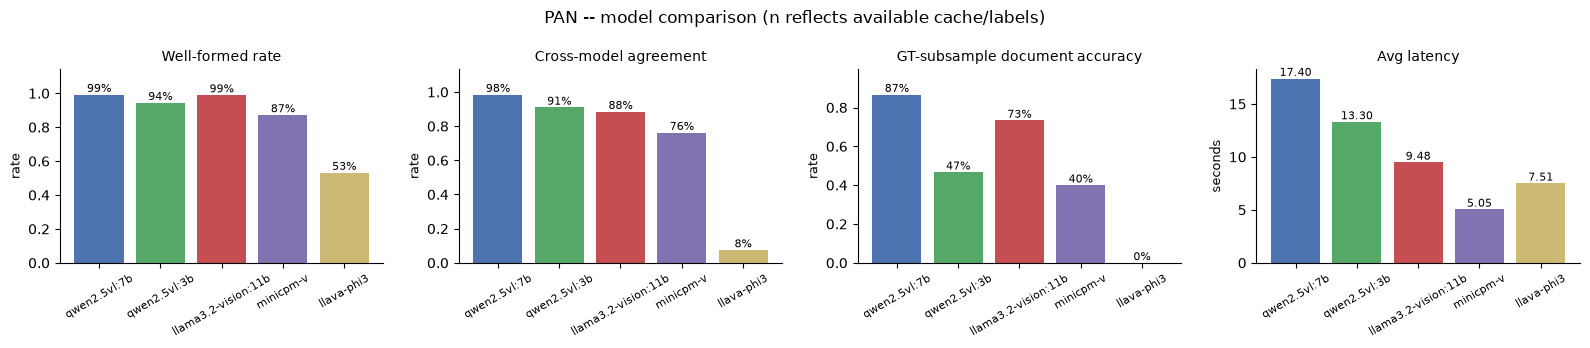

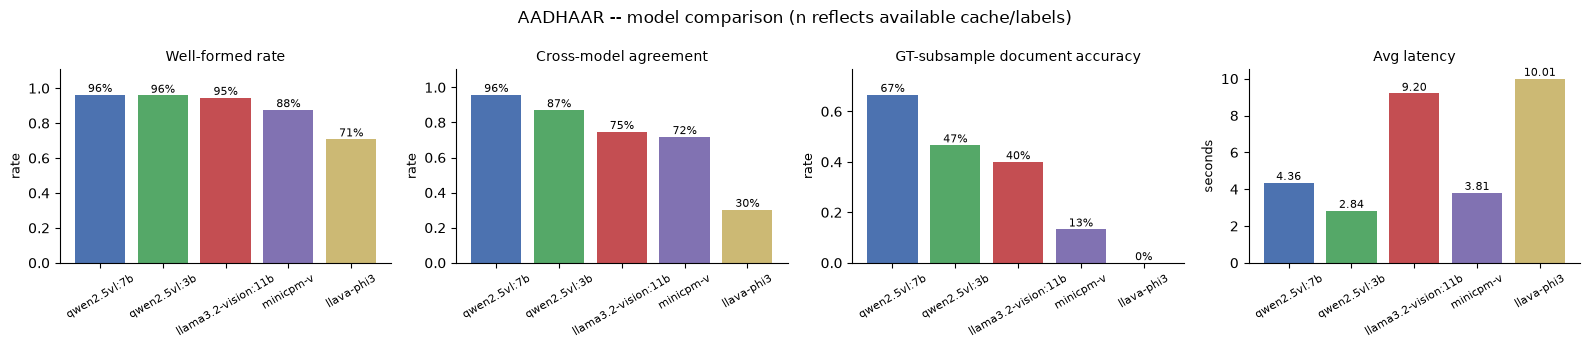

In [7]:
MODEL_COLORS = {
    "qwen2.5vl:7b": "#4C72B0",
    "qwen2.5vl:3b": "#55A868",
    "llama3.2-vision:11b": "#C44E52",
    "minicpm-v": "#8172B2",
    "llava-phi3": "#CCB974",
}


def grouped_bar(ax, doc_type, metric_by_model, title, ylabel):
    models_with_data = [m for m in MODELS if m in metric_by_model]
    values = [metric_by_model[m] for m in models_with_data]
    colors = [MODEL_COLORS[m] for m in models_with_data]
    bars = ax.bar(models_with_data, values, color=colors)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_ylim(0, max(values) * 1.15 if values and ylabel != "seconds" else None)
    ax.tick_params(axis="x", labelrotation=30, labelsize=8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for bar, v in zip(bars, values):
        label = f"{v:.2f}" if ylabel == "seconds" else f"{v*100:.0f}%"
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), label,
                ha="center", va="bottom", fontsize=8)


for doc_type in DOC_TYPES:
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
    fig.suptitle(f"{doc_type.upper()} -- model comparison (n reflects available cache/labels)", fontsize=12)

    avg_wellformed = {
        m: statistics.mean(wellformed_stats[doc_type][m].values())
        for m in wellformed_stats.get(doc_type, {})
    }
    avg_agreement = {
        m: statistics.mean(agreement_stats[doc_type][m].values())
        for m in agreement_stats.get(doc_type, {})
        if any(agreement_stats[doc_type][m].values())
    }
    gt_doc_acc = {
        m: gt_accuracy_stats[doc_type][m]["document"]
        for m in gt_accuracy_stats.get(doc_type, {})
    }
    avg_latency = {
        m: latency_stats[doc_type][m]["avg"]
        for m in latency_stats.get(doc_type, {})
    }

    grouped_bar(axes[0], doc_type, avg_wellformed, "Well-formed rate", "rate")
    grouped_bar(axes[1], doc_type, avg_agreement, "Cross-model agreement", "rate")
    grouped_bar(axes[2], doc_type, gt_doc_acc, "GT-subsample document accuracy", "rate")
    grouped_bar(axes[3], doc_type, avg_latency, "Avg latency", "seconds")

    plt.tight_layout()
    plt.show()


## 7. Notes for the report / DevDay talk

- **Well-formed rate** answers "does the model even attempt a plausible answer" -- a floor, not a ceiling. A model can be 100% well-formed and still wrong (e.g. a confidently formatted but incorrect PAN number).
- **Cross-model agreement** is the real headline metric at scale (n=100+ per doc type) -- five independently-trained models converging on the same value is a strong (if imperfect) accuracy signal. Low agreement on a field is worth spot-checking against the manual ground truth to understand whether it's genuine ambiguity (glare, occlusion) or a systematic model weakness.
- **Manual ground-truth accuracy** is the one number in this notebook that's real, measured accuracy rather than a proxy -- small sample size, so treat it as validation for the agreement metric's direction, not as a statistically tight estimate on its own.
- **Aadhaar vs. PAN comparison** is the direct answer to the original "different formats across documents" framing -- compare each model's relative ranking across the two document types, not just the absolute numbers.
- **Next optional step (deferred, time permitting)**: the same fixed image samples and `extraction_lib.py` schema/prompt scaffolding are already set up to extend to a cloud model (Bedrock/OpenRouter) for a local-vs-cloud comparison, if there's time before the report is due.